# Notebook 06 — Résilience Bancaire & Reverse Stress Test
## Impact sur CET1, Courbe de Résilience, Point de Rupture

**Objectif :** Mesurer l'impact des chocs sur le ratio CET1, construire la courbe
de résilience et identifier par Reverse Stress Test le choc minimum qui amène
la banque au seuil réglementaire Bâle III (CET1 = 4.5%).

**Formule CET1 :**
```
CET1_post_stress = CET1_initial - ΔECL × (1 - tax_rate) / RWA
CET1_initial = 12% | RWA = EAD_total | tax_rate = 30%
```


## Positionnement bancaire du notebook

**Role dans la plateforme**  
Mesurer la resilience capital: CET1, RWA, shortfall, reverse stress test et point de rupture.

**Lecture expert bancaire**  
Bale regarde la solvabilite: RWA, capital stack, seuils et actions de remediation si la banque ne resiste pas.

**Sorties attendues**  
cet1_resilience_table.csv, resilience_curve.csv, reverse_stress_test.csv, basel_capital_metrics.csv.

**Transition logique**  
Le notebook 07 consolide validation, gouvernance modele et coherence des sorties.

In [11]:
import sys
sys.path.insert(0, '..')

import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import joblib
from pathlib import Path

plt.rcParams['figure.figsize'] = (12, 5)
sns.set_style('whitegrid')

OUTPUT_DIR = Path('../outputs')
MODELS_DIR = OUTPUT_DIR / 'models'
RESULTS_DIR = OUTPUT_DIR / 'results'

from src.resilience import (
    CET1_INITIAL, CET1_REGULATORY_MIN, CET1_TOTAL_MIN,
    compute_cet1_impact, compute_cet1_table,
    resilience_curve, reverse_stress_test, generate_resilience_report
)
from src.stress_scenarios import SCENARIOS, SCENARIO_LABELS, SCENARIO_COLORS, ACTIVE_STRESS_SCENARIOS

print('Imports OK')
print(f'CET1 initial  : {CET1_INITIAL:.1%}')
print(f'Seuil Bâle III: {CET1_REGULATORY_MIN:.1%}')


Imports OK
CET1 initial  : 12.0%
Seuil Bâle III: 4.5%


---
## 1. Chargement


In [12]:
from src.data_prep import get_pd_features

df = pd.read_parquet(OUTPUT_DIR / 'loan_clean.parquet')
df_ecl = pd.read_parquet(OUTPUT_DIR / 'ecl_baseline.parquet')
df['PD_pred']   = df_ecl['PD_pred'].values
df['ECL_ifrs9'] = df_ecl['ECL_ifrs9'].values

features = get_pd_features(df)
ecl_baseline = df['ECL_ifrs9'].sum() / 1e6
ead_total    = df['EAD'].sum() / 1e6

pd_models = {f.stem.replace('pd_model_', ''): joblib.load(f)
              for f in MODELS_DIR.glob('pd_model_*.pkl')}

try:
    results_df = pd.read_csv(MODELS_DIR / 'pd_model_comparison.csv', index_col=0)
    champion = results_df['AUC-ROC'].idxmax().lower()
except:
    champion = list(pd_models.keys())[0]

pd_champion = pd_models[champion]
sat_pd_models   = joblib.load(MODELS_DIR / 'satellite_pd_models.pkl')
sat_pd_features = joblib.load(MODELS_DIR / 'satellite_pd_features.pkl')

try:
    sat_results = pd.read_csv(MODELS_DIR / 'satellite_pd_comparison.csv', index_col=0)
    sat_champion = sat_results['RMSE'].idxmin()
except:
    sat_champion = 'OLS'

# Charger les résultats de stress
summary_df = pd.read_csv(RESULTS_DIR / 'stress_ecl_summary.csv')

print(f'ECL Baseline : ${ecl_baseline:,.2f} M')
print(f'EAD Total    : ${ead_total:,.2f} M')
print(f'CET1 initial : {CET1_INITIAL:.1%}')
print(f'RWA (=EAD)   : ${ead_total:,.2f} M')


ECL Baseline : $3,803.04 M
EAD Total    : $34,004.21 M
CET1 initial : 12.0%
RWA (=EAD)   : $34,004.21 M


---
## 2. Impact CET1 par Scénario


In [13]:
from src.stress_scenarios import compute_stress_ecl

# Re-calculer les résultats de stress pour les CET1
scenarios_to_run = ACTIVE_STRESS_SCENARIOS
stressed_results, _ = compute_stress_ecl(
    df, pd_champion, features,
    sat_pd_models, sat_pd_features, sat_champion,
    scenarios=scenarios_to_run,
)

# Calcul CET1 pour chaque scénario
cet1_table = compute_cet1_table(ecl_baseline, stressed_results, ead_total * 1e6)

print('\n=== Tableau CET1 par Scénario ===')
cols_display = ['CET1_initial_%', 'ΔCET1_%', 'CET1_post_stress_%', 'ΔECL_M$', 'zone']
cols_available = [c for c in cols_display if c in cet1_table.columns]
display(cet1_table[cols_available])



→ Scénario : Adverse
  ECL stressed : $7,764.1 M (×2.04 vs baseline)

→ Scénario : Severe
  ECL stressed : $8,431.2 M (×2.22 vs baseline)

→ Scénario : Choc Taux
  ECL stressed : $8,726.4 M (×2.29 vs baseline)

→ Scénario : Choc Marche 2018
  ECL stressed : $4,132.8 M (×1.09 vs baseline)

→ Scénario : Inflation Ukraine 2022
  ECL stressed : $6,252.5 M (×1.64 vs baseline)

→ Scénario : Crise 2008
  ECL stressed : $9,589.2 M (×2.52 vs baseline)

→ Scénario : Crise COVID-19
  ECL stressed : $10,043.0 M (×2.64 vs baseline)

✓ Résultats sauvegardés : C:\Users\user\Documents\pfafinal\projet_Far7ti\outputs\results\stress_ecl_summary.csv
Table CET1 sauvegardée : C:\Users\user\Documents\pfafinal\projet_Far7ti\outputs\results\cet1_resilience_table.csv

=== Tableau CET1 par Scénario ===


,CET1_initial_%,ΔCET1_%,CET1_post_stress_%,ΔECL_M$,zone
Scenario,,,,,
Adverse,12.0,-8.15,3.85,3961.03,🚨 Critique (CET1 < 4.5% — Bâle III)
Severe,12.0,-9.53,2.47,4628.20,🚨 Critique (CET1 < 4.5% — Bâle III)
Choc Taux,12.0,-10.14,1.86,4923.32,🚨 Critique (CET1 < 4.5% — Bâle III)
Choc Marche 2018,12.0,-0.68,11.32,329.75,✓ Résilient (CET1 ≥ 7%)
Inflation Ukraine 2022,12.0,-5.04,6.96,2449.43,⚠ Attention (4.5% ≤ CET1 < 7%)
Crise 2008,12.0,-11.91,0.09,5786.18,🚨 Critique (CET1 < 4.5% — Bâle III)
Crise COVID-19,12.0,-12.85,-0.85,6239.95,💥 Rupture (CET1 < 0% — Défaillance)


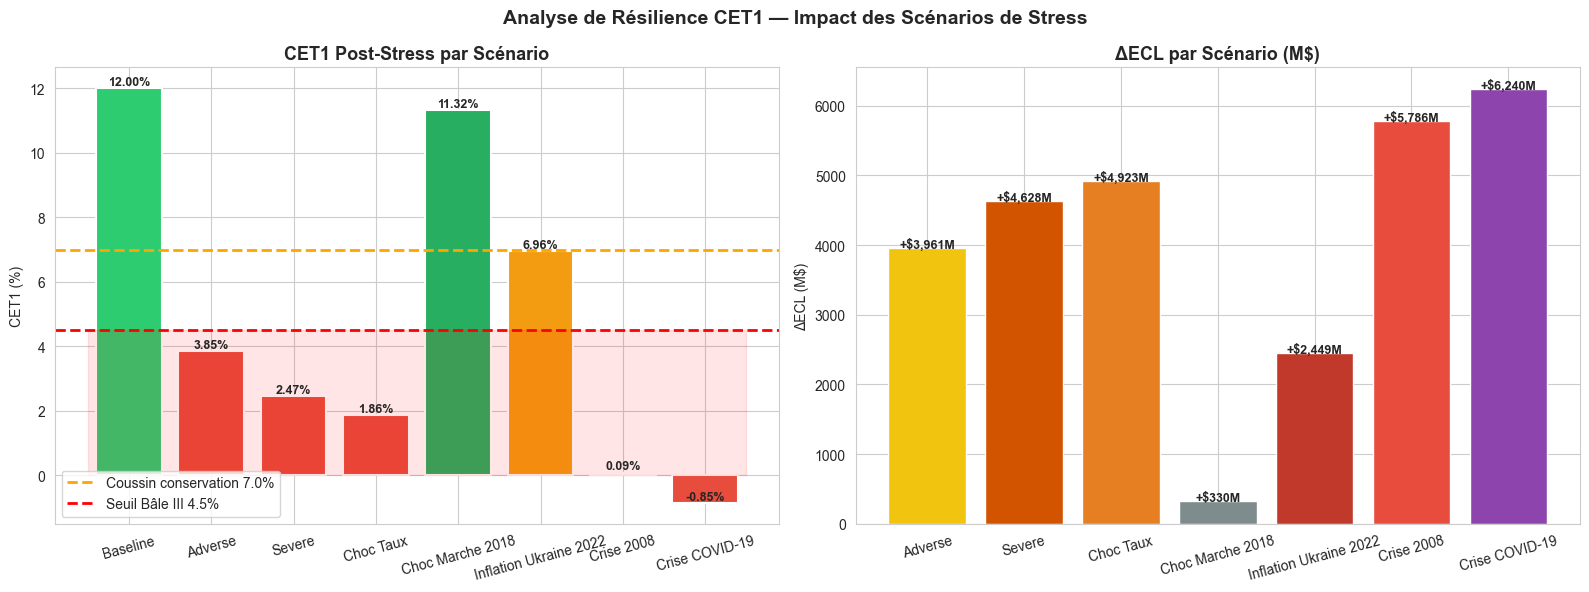

In [14]:
# Visualisation CET1 par scénario
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

scenarios_plot = ['Baseline'] + list(cet1_table.index)
cet1_vals = [CET1_INITIAL * 100] + list(cet1_table['CET1_post_stress_%'])
delta_ecl_vals = [0] + list(cet1_table['ΔECL_M$'])

colors_bar = ['#2ecc71']
for v in cet1_vals[1:]:
    if v >= 7:
        colors_bar.append('#27ae60')
    elif v >= 4.5:
        colors_bar.append('#f39c12')
    else:
        colors_bar.append('#e74c3c')

# CET1 post-stress
bars = axes[0].bar(scenarios_plot, cet1_vals, color=colors_bar, edgecolor='white', linewidth=1.5)
axes[0].axhline(CET1_TOTAL_MIN * 100, color='orange', linestyle='--', linewidth=2,
                 label=f'Coussin conservation {CET1_TOTAL_MIN:.1%}')
axes[0].axhline(CET1_REGULATORY_MIN * 100, color='red', linestyle='--', linewidth=2,
                 label=f'Seuil Bâle III {CET1_REGULATORY_MIN:.1%}')
axes[0].fill_between([-0.5, len(scenarios_plot)-0.5], [0, 0],
                      [CET1_REGULATORY_MIN * 100, CET1_REGULATORY_MIN * 100],
                      alpha=0.1, color='red')
for bar, v in zip(bars, cet1_vals):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.1,
                  f'{v:.2f}%', ha='center', fontweight='bold', fontsize=9)
axes[0].set_title('CET1 Post-Stress par Scénario', fontweight='bold', fontsize=13)
axes[0].set_ylabel('CET1 (%)')
axes[0].legend(loc='lower left')
plt.setp(axes[0].xaxis.get_majorticklabels(), rotation=15)

# ΔECL par scénario
sc_for_plot = list(cet1_table.index)
delta_for_plot = list(cet1_table['ΔECL_M$'])
sc_colors_plot = [SCENARIO_COLORS.get(
    [k for k, v in SCENARIO_LABELS.items() if v == s][0] if any(v == s for k, v in SCENARIO_LABELS.items()) else 'baseline',
    '#e74c3c') for s in sc_for_plot]

bars2 = axes[1].bar(sc_for_plot, delta_for_plot, color=sc_colors_plot, edgecolor='white')
for bar, v in zip(bars2, delta_for_plot):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                  f'+${v:,.0f}M', ha='center', fontweight='bold', fontsize=9)
axes[1].set_title('ΔECL par Scénario (M$)', fontweight='bold', fontsize=13)
axes[1].set_ylabel('ΔECL (M$)')
plt.setp(axes[1].xaxis.get_majorticklabels(), rotation=15)

plt.suptitle('Analyse de Résilience CET1 — Impact des Scénarios de Stress',
              fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fig_31_cet1_scenarios.png', dpi=150, bbox_inches='tight')
plt.show()


---
## 3. Courbe de Résilience


In [15]:
print('Calcul de la courbe de résilience (peut prendre quelques minutes)...')
curve_df = resilience_curve(
    df, ecl_baseline, pd_champion, features,
    sat_pd_models, sat_pd_features, sat_champion,
    n_points=25,
    max_intensity=2.5,
)


Calcul de la courbe de résilience (peut prendre quelques minutes)...
Calcul de la courbe de résilience...
Courbe de résilience sauvegardée (25 points) : C:\Users\user\Documents\pfafinal\projet_Far7ti\outputs\results\resilience_curve.csv


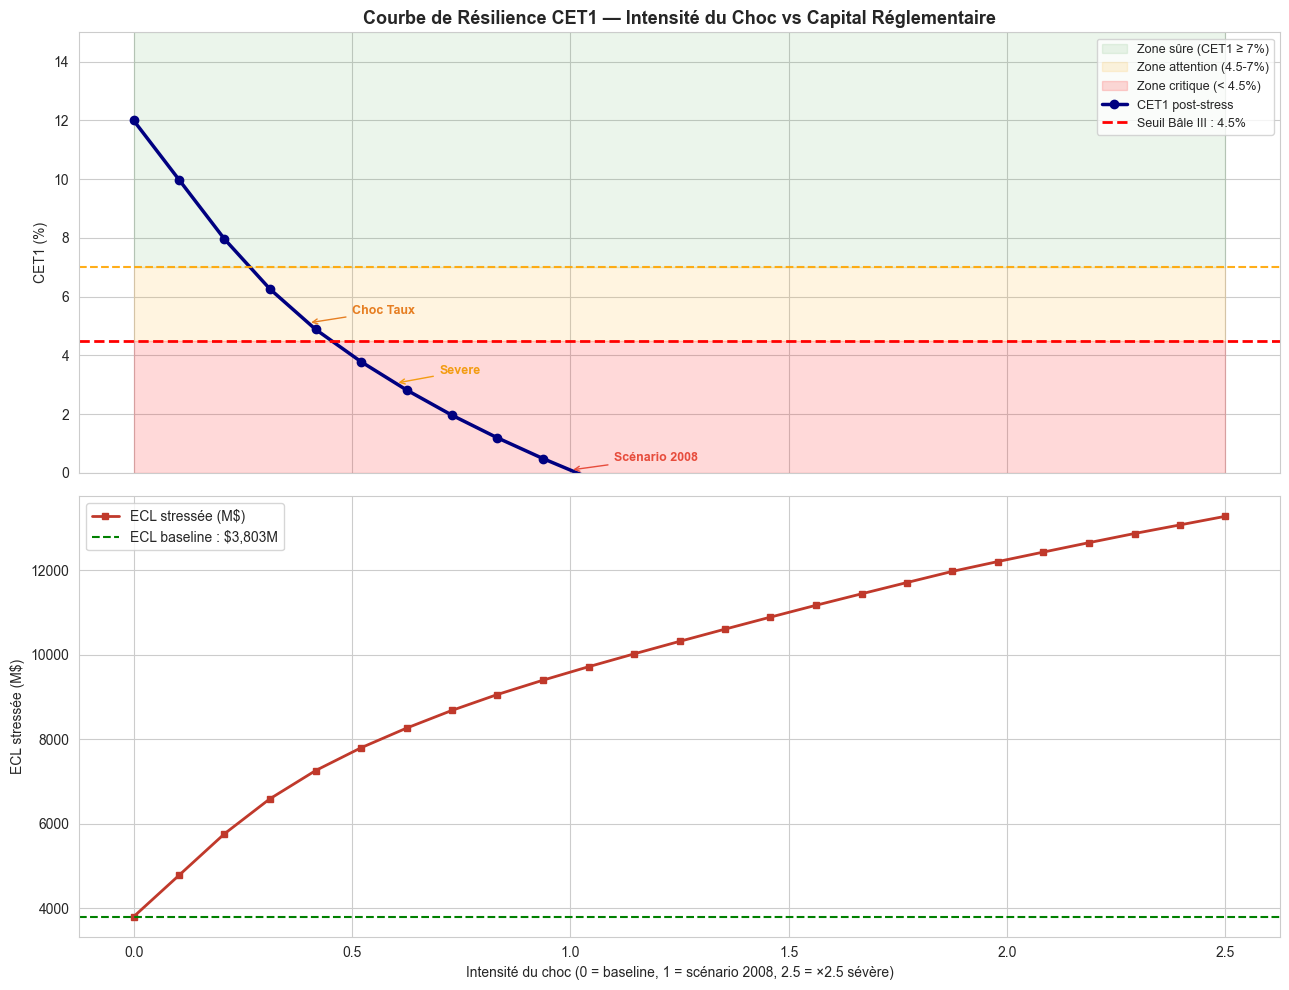


🚨 Première intensité critique (CET1 < 4.5%) : ×0.52
   UNRATE correspondant  : 7.1%
   GDP growth            : -1.3%


In [16]:
# Plot courbe de résilience
fig, axes = plt.subplots(2, 1, figsize=(13, 10), sharex=True)

# Zone de couleur selon seuils CET1
x = curve_df['intensity']
cet1 = curve_df['CET1_%']

# Zone résiliente
axes[0].fill_between(x, CET1_TOTAL_MIN * 100, 15,
                      alpha=0.08, color='green', label='Zone sûre (CET1 ≥ 7%)')
axes[0].fill_between(x, CET1_REGULATORY_MIN * 100, CET1_TOTAL_MIN * 100,
                      alpha=0.12, color='orange', label='Zone attention (4.5-7%)')
axes[0].fill_between(x, 0, CET1_REGULATORY_MIN * 100,
                      alpha=0.15, color='red', label='Zone critique (< 4.5%)')

axes[0].plot(x, cet1, 'o-', color='navy', linewidth=2.5, markersize=6, label='CET1 post-stress')
axes[0].axhline(CET1_TOTAL_MIN * 100, color='orange', linestyle='--', linewidth=1.5, alpha=0.9)
axes[0].axhline(CET1_REGULATORY_MIN * 100, color='red', linestyle='--', linewidth=2,
                 label=f'Seuil Bâle III : {CET1_REGULATORY_MIN:.1%}')

# Marquer les scénarios prédéfinis
for intensity_mark, label, color_mark in [
    (1.0, 'Scénario 2008', '#e74c3c'),
    (0.6, 'Severe', '#f39c12'),
    (0.4, 'Choc Taux', '#e67e22'),
]:
    if intensity_mark <= x.max():
        cet1_mark = np.interp(intensity_mark, x, cet1)
        axes[0].annotate(label, xy=(intensity_mark, cet1_mark),
                          xytext=(intensity_mark + 0.1, cet1_mark + 0.3),
                          arrowprops=dict(arrowstyle='->', color=color_mark),
                          color=color_mark, fontweight='bold', fontsize=9)

axes[0].set_ylabel('CET1 (%)')
axes[0].set_title('Courbe de Résilience CET1 — Intensité du Choc vs Capital Réglementaire',
                   fontweight='bold', fontsize=13)
axes[0].legend(loc='upper right', fontsize=9)
axes[0].set_ylim(0, 15)

# Panel bas : ECL stressée
axes[1].plot(x, curve_df['ECL_stressed_M$'], 's-', color='#c0392b', linewidth=2,
              markersize=5, label='ECL stressée (M$)')
axes[1].axhline(ecl_baseline, color='green', linestyle='--', linewidth=1.5,
                 label=f'ECL baseline : ${ecl_baseline:,.0f}M')
axes[1].set_ylabel('ECL stressée (M$)')
axes[1].set_xlabel('Intensité du choc (0 = baseline, 1 = scénario 2008, 2.5 = ×2.5 sévère)')
axes[1].legend()

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fig_32_resilience_curve.png', dpi=150, bbox_inches='tight')
plt.show()

# Premier point critique
crit = curve_df[curve_df['is_critical']]
if len(crit) > 0:
    print(f'\n🚨 Première intensité critique (CET1 < 4.5%) : ×{crit.iloc[0]["intensity"]:.2f}')
    print(f'   UNRATE correspondant  : {crit.iloc[0]["scenario_unrate_%"]:.1f}%')
    print(f'   GDP growth            : {crit.iloc[0]["scenario_gdp_%"]:.1f}%')
else:
    print('✓ CET1 reste > 4.5% sur toute la plage testée — portefeuille très résilient')


---
## 4. Reverse Stress Test


In [17]:
print('=== Reverse Stress Test — Point de Rupture CET1 = 4.5% ===')
rst = reverse_stress_test(
    df, ecl_baseline, pd_champion, features,
    sat_pd_models, sat_pd_features, sat_champion,
    target_cet1=CET1_REGULATORY_MIN,
)


=== Reverse Stress Test — Point de Rupture CET1 = 4.5% ===

=== Reverse Stress Test ===
Recherche de l'intensité qui amène CET1 → 4.5%...

✓ Point de rupture trouvé à intensité × 0.445
   CET1 atteint          : 4.56%
   UNRATE critique       : 6.7%
   PIB growth critique   : -0.8%
   Fed Funds critique    : 1.5%
   ECL critique          : $7,419.1 M (×1.95)


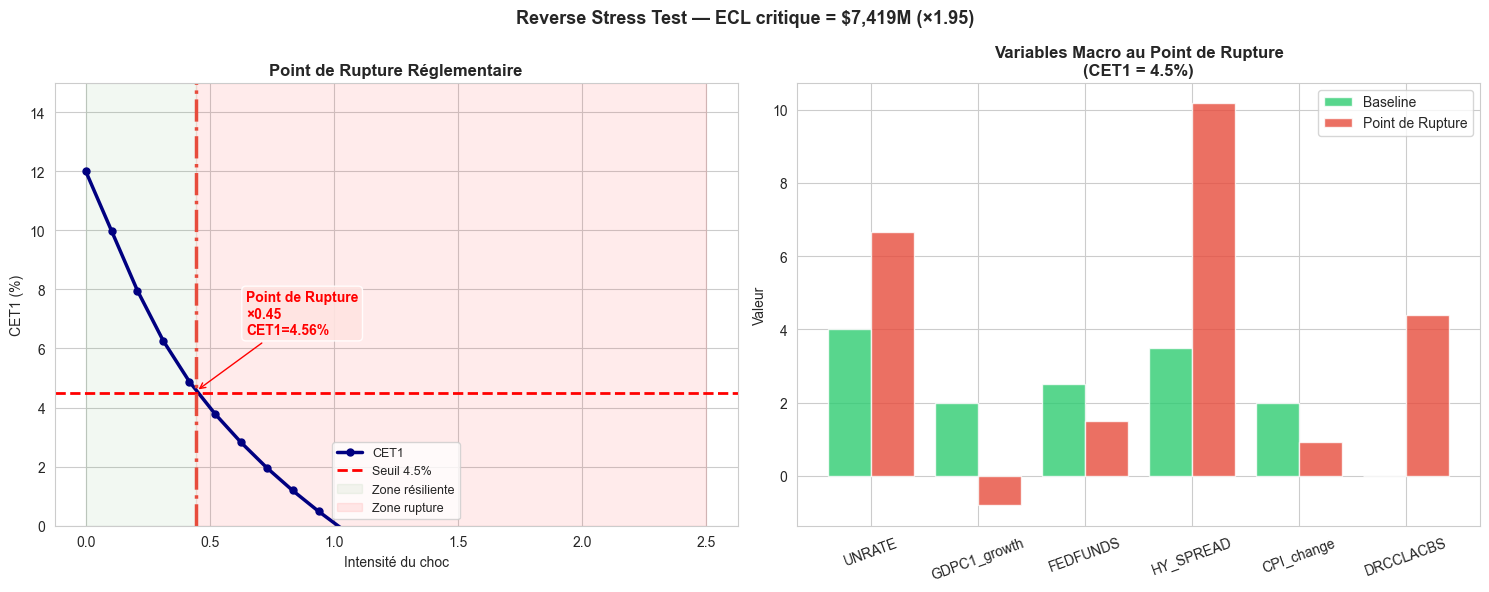

In [18]:
if rst.get('intensity_critical') is not None:
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    
    # Visualisation du point de rupture sur la courbe de résilience
    axes[0].plot(curve_df['intensity'], curve_df['CET1_%'], 'o-',
                  color='navy', linewidth=2.5, markersize=5, label='CET1')
    axes[0].axhline(CET1_REGULATORY_MIN * 100, color='red', linestyle='--', linewidth=2,
                     label=f'Seuil 4.5%')
    axes[0].axvline(rst['intensity_critical'], color='#e74c3c', linestyle='-.', linewidth=2.5)
    axes[0].annotate(
        f'Point de Rupture\n×{rst["intensity_critical"]:.2f}\nCET1={rst["cet1_achieved_%"]:.2f}%',
        xy=(rst['intensity_critical'], rst['cet1_achieved_%']),
        xytext=(rst['intensity_critical'] + 0.2, CET1_REGULATORY_MIN * 100 + 2),
        arrowprops=dict(arrowstyle='->', color='red'),
        color='red', fontweight='bold', fontsize=10,
        bbox=dict(boxstyle='round', facecolor='mistyrose', alpha=0.9)
    )
    axes[0].fill_between([0, rst['intensity_critical']], [0, 0], [15, 15],
                          alpha=0.05, color='green', label='Zone résiliente')
    axes[0].fill_between([rst['intensity_critical'], curve_df['intensity'].max()],
                          [0, 0], [15, 15], alpha=0.08, color='red', label='Zone rupture')
    axes[0].set_ylim(0, 15)
    axes[0].set_xlabel('Intensité du choc')
    axes[0].set_ylabel('CET1 (%)')
    axes[0].set_title('Point de Rupture Réglementaire', fontweight='bold')
    axes[0].legend(fontsize=9)
    
    # Tableau des valeurs macro au point critique
    macro_crit = rst['macro_critical']
    baseline_vals = {k: v for k, v in {
        'UNRATE': 4.0, 'GDPC1_growth': 2.0, 'FEDFUNDS': 2.5,
        'HY_SPREAD': 3.5, 'CPI_change': 2.0
    }.items() if k in macro_crit}
    
    vars_plot = list(macro_crit.keys())
    base_v = [baseline_vals.get(k, 0) for k in vars_plot]
    crit_v = [macro_crit[k] for k in vars_plot]
    
    x = np.arange(len(vars_plot))
    axes[1].bar(x - 0.2, base_v, 0.4, label='Baseline', color='#2ecc71', alpha=0.8)
    axes[1].bar(x + 0.2, crit_v, 0.4, label='Point de Rupture', color='#e74c3c', alpha=0.8)
    axes[1].set_xticks(x)
    axes[1].set_xticklabels(vars_plot, rotation=20)
    axes[1].set_title(f'Variables Macro au Point de Rupture\n(CET1 = 4.5%)',
                       fontweight='bold')
    axes[1].set_ylabel('Valeur')
    axes[1].legend()
    
    plt.suptitle(f'Reverse Stress Test — ECL critique = ${rst["ECL_critical_M$"]:,.0f}M (×{rst["ECL_lift"]:.2f})',
                  fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / 'fig_33_reverse_stress_test.png', dpi=150, bbox_inches='tight')
    plt.show()


---
## 5. Rapport Final de Résilience


In [19]:
generate_resilience_report(ecl_baseline, cet1_table, curve_df, rst)



RAPPORT DE RÉSILIENCE BANCAIRE — IFRS 9 STRESS TESTING

CET1 initial         : 12.0%
Seuil réglementaire  : 4.5% (Bâle III)
ECL baseline         : $3,803.0 M

--- Impact par Scénario ---
                        CET1_post_stress_%  ΔCET1_%  ΔECL_M$                                 zone
Scenario                                                                                         
Adverse                               3.85    -8.15  3961.03  🚨 Critique (CET1 < 4.5% — Bâle III)
Severe                                2.47    -9.53  4628.20  🚨 Critique (CET1 < 4.5% — Bâle III)
Choc Taux                             1.86   -10.14  4923.32  🚨 Critique (CET1 < 4.5% — Bâle III)
Choc Marche 2018                     11.32    -0.68   329.75              ✓ Résilient (CET1 ≥ 7%)
Inflation Ukraine 2022                6.96    -5.04  2449.43       ⚠ Attention (4.5% ≤ CET1 < 7%)
Crise 2008                            0.09   -11.91  5786.18  🚨 Critique (CET1 < 4.5% — Bâle III)
Crise COVID-19              

,CET1_initial_%,ECL_baseline_M$,ECL_stressed_M$,ΔECL_M$,ΔECL_net_M$,ΔCET1_%,CET1_post_stress_%,RWA_M$,Capital_initial_M$,Capital_post_M$,Shortfall_4_5_M$,Shortfall_7_0_M$,zone,color,management_action,is_critical
Scenario,,,,,,,,,,,,,,,,
Adverse,12.0,3803.04,7764.06,3961.03,2772.72,-8.15,3.85,34004.21,4080.51,1307.79,222.40,1072.51,🚨 Critique (CET1 < 4.5% — Bâle III),red,"Plan de recapitalisation: injection capital, c...",True
Severe,12.0,3803.04,8431.24,4628.20,3239.74,-9.53,2.47,34004.21,4080.51,840.76,689.43,1539.53,🚨 Critique (CET1 < 4.5% — Bâle III),red,"Plan de recapitalisation: injection capital, c...",True
Choc Taux,12.0,3803.04,8726.36,4923.32,3446.33,-10.14,1.86,34004.21,4080.51,634.18,896.01,1746.12,🚨 Critique (CET1 < 4.5% — Bâle III),red,"Plan de recapitalisation: injection capital, c...",True
Choc Marche 2018,12.0,3803.04,4132.79,329.75,230.83,-0.68,11.32,34004.21,4080.51,3849.68,0.00,0.00,✓ Résilient (CET1 ≥ 7%),green,Surveillance normale et maintien des coussins.,False
Inflation Ukraine 2022,12.0,3803.04,6252.47,2449.43,1714.60,-5.04,6.96,34004.21,4080.51,2365.90,0.00,14.39,⚠ Attention (4.5% ≤ CET1 < 7%),orange,Plan de conservation capital: limiter dividend...,False
Crise 2008,12.0,3803.04,9589.22,5786.18,4050.33,-11.91,0.09,34004.21,4080.51,30.18,1500.01,2350.12,🚨 Critique (CET1 < 4.5% — Bâle III),red,"Plan de recapitalisation: injection capital, c...",True
Crise COVID-19,12.0,3803.04,10042.99,6239.95,4367.97,-12.85,-0.85,34004.21,4080.51,-287.46,1817.65,2667.76,💥 Rupture (CET1 < 0% — Défaillance),darkred,Resolution/restructuration: recapitalisation u...,True


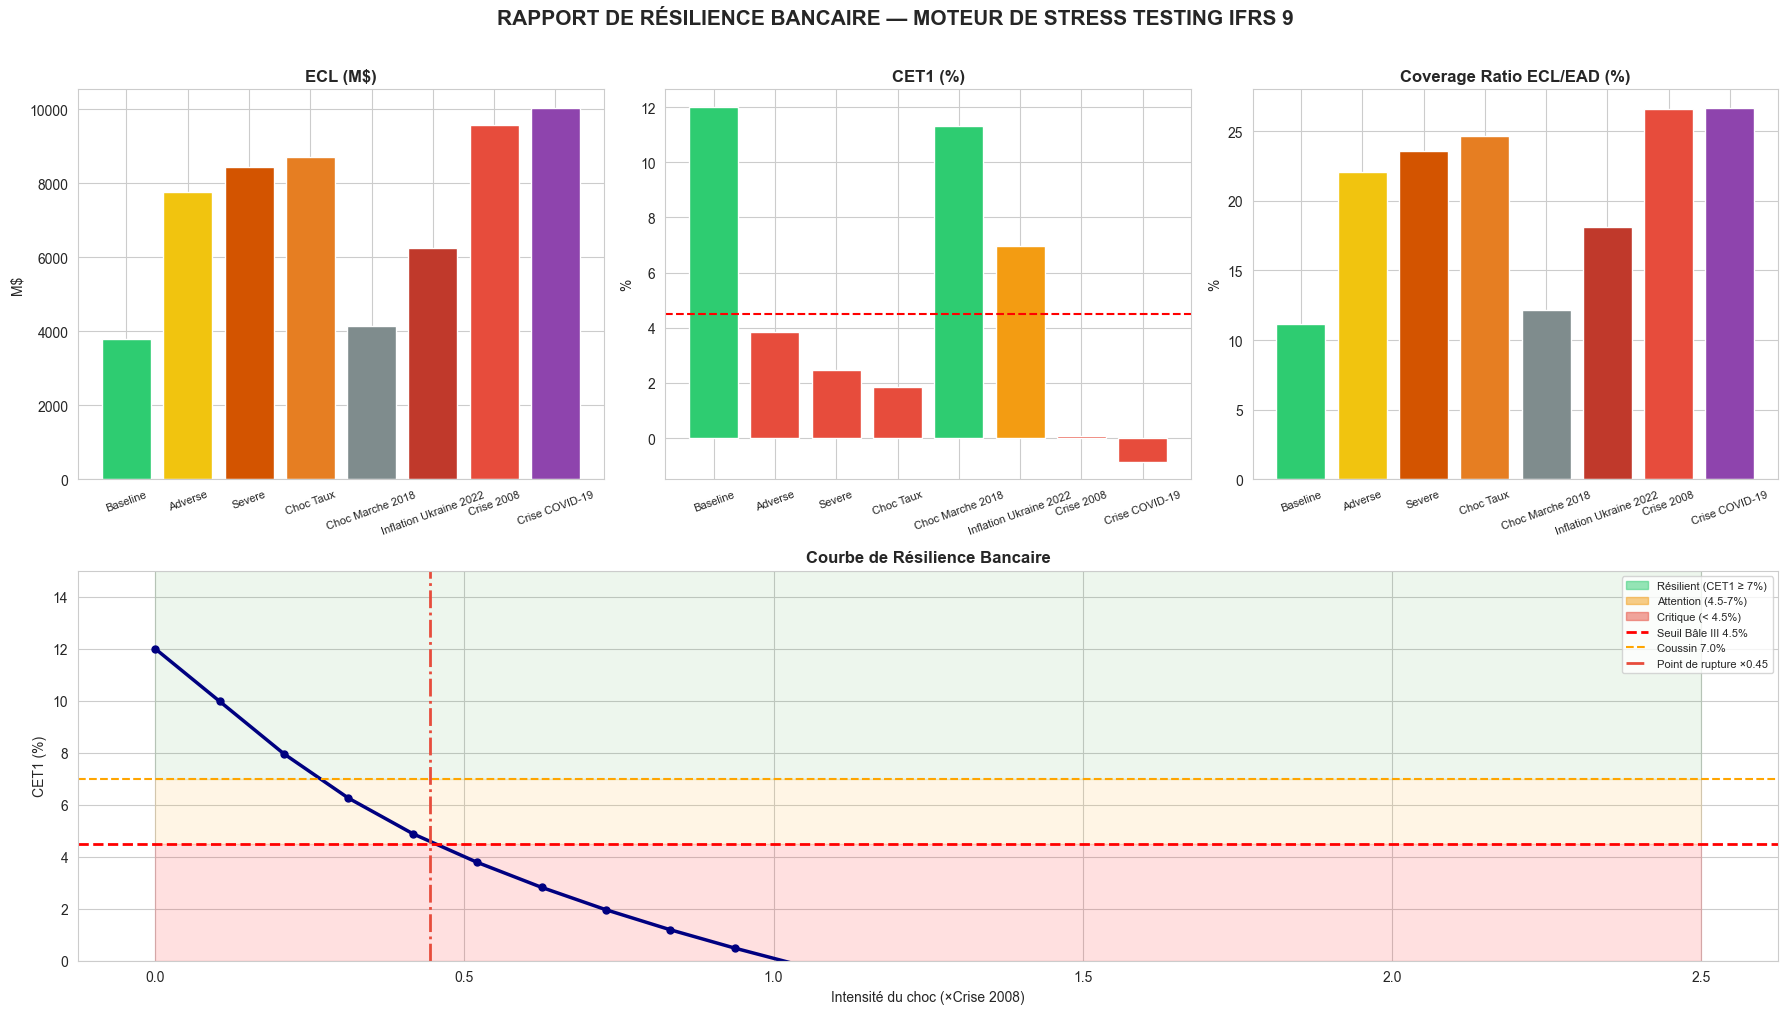


=== Notebook 05 terminé — Analyse de Résilience Complète ===


In [20]:
# Dashboard final — synthèse visuelle
fig = plt.figure(figsize=(18, 10))

# Layout 2×3
ax1 = fig.add_subplot(2, 3, 1)  # ECL par scénario
ax2 = fig.add_subplot(2, 3, 2)  # CET1 par scénario
ax3 = fig.add_subplot(2, 3, 3)  # Coverage ratio
ax4 = fig.add_subplot(2, 1, 2)  # Courbe résilience (pleine largeur)

# Panel 1 : ECL
ecl_vals_all = [ecl_baseline]
sc_labels_all = ['Baseline']
sc_colors_all = ['#2ecc71']
for sc_name, df_s in stressed_results.items():
    ecl_vals_all.append(df_s['ECL_stressed'].sum() / 1e6)
    sc_labels_all.append(SCENARIO_LABELS.get(sc_name, sc_name))
    sc_colors_all.append(SCENARIO_COLORS.get(sc_name, '#e74c3c'))

ax1.bar(range(len(sc_labels_all)), ecl_vals_all, color=sc_colors_all, edgecolor='white')
ax1.set_xticks(range(len(sc_labels_all)))
ax1.set_xticklabels(sc_labels_all, rotation=20, fontsize=8)
ax1.set_title('ECL (M$)', fontweight='bold')
ax1.set_ylabel('M$')

# Panel 2 : CET1
cet1_all = [CET1_INITIAL * 100] + list(cet1_table['CET1_post_stress_%'])
sc_for_cet1 = ['Baseline'] + list(cet1_table.index)
cet1_colors = []
for v in cet1_all:
    if v >= 7:
        cet1_colors.append('#2ecc71')
    elif v >= 4.5:
        cet1_colors.append('#f39c12')
    else:
        cet1_colors.append('#e74c3c')

ax2.bar(range(len(sc_for_cet1)), cet1_all, color=cet1_colors, edgecolor='white')
ax2.axhline(4.5, color='red', linestyle='--', linewidth=1.5)
ax2.set_xticks(range(len(sc_for_cet1)))
ax2.set_xticklabels(sc_for_cet1, rotation=20, fontsize=8)
ax2.set_title('CET1 (%)', fontweight='bold')
ax2.set_ylabel('%')

# Panel 3 : Coverage
cov_vals = [ecl_baseline / ead_total * 100]
for df_s in stressed_results.values():
    cov_vals.append(df_s['ECL_stressed'].sum() / df_s['EAD_stressed'].sum() * 100)
ax3.bar(range(len(sc_labels_all)), cov_vals, color=sc_colors_all, edgecolor='white')
ax3.set_xticks(range(len(sc_labels_all)))
ax3.set_xticklabels(sc_labels_all, rotation=20, fontsize=8)
ax3.set_title('Coverage Ratio ECL/EAD (%)', fontweight='bold')
ax3.set_ylabel('%')

# Panel 4 : Courbe de résilience
x = curve_df['intensity']
ax4.fill_between(x, 7, 15, alpha=0.07, color='green')
ax4.fill_between(x, 4.5, 7, alpha=0.10, color='orange')
ax4.fill_between(x, 0, 4.5, alpha=0.12, color='red')
ax4.plot(x, curve_df['CET1_%'], 'o-', color='navy', linewidth=2.5, markersize=5)
ax4.axhline(4.5, color='red', linestyle='--', linewidth=2, label='Seuil Bâle III 4.5%')
ax4.axhline(7.0, color='orange', linestyle='--', linewidth=1.5, label='Coussin 7.0%')
if rst.get('intensity_critical'):
    ax4.axvline(rst['intensity_critical'], color='#e74c3c', linestyle='-.', linewidth=2,
                 label=f'Point de rupture ×{rst["intensity_critical"]:.2f}')
ax4.set_xlabel('Intensité du choc (×Crise 2008)')
ax4.set_ylabel('CET1 (%)')
ax4.set_title('Courbe de Résilience Bancaire', fontweight='bold')
ax4.legend(loc='upper right')
ax4.set_ylim(0, 15)

green_p  = mpatches.Patch(color='#2ecc71', alpha=0.5, label='Résilient (CET1 ≥ 7%)')
orange_p = mpatches.Patch(color='#f39c12', alpha=0.5, label='Attention (4.5-7%)')
red_p    = mpatches.Patch(color='#e74c3c', alpha=0.5, label='Critique (< 4.5%)')
ax4.legend(handles=[green_p, orange_p, red_p] + ax4.get_legend_handles_labels()[0],
            loc='upper right', fontsize=8)

plt.suptitle('RAPPORT DE RÉSILIENCE BANCAIRE — MOTEUR DE STRESS TESTING IFRS 9',
              fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fig_34_resilience_dashboard.png', dpi=150, bbox_inches='tight')
plt.show()

print('\n=== Notebook 05 terminé — Analyse de Résilience Complète ===')


## Controle bancaire complementaire: RWA et capital stack Bale

Cette section relie la resilience CET1 aux RWA et aux ratios prudentiels.
Elle complete l'analyse de resilience par une lecture Bale.

In [21]:
from pathlib import Path
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
basel_path = ROOT / "outputs" / "results" / "basel_capital_metrics.csv"
segment_path = ROOT / "outputs" / "results" / "regulatory_segment_summary.csv"

if basel_path.exists():
    display(pd.read_csv(basel_path).T)
else:
    print("basel_capital_metrics.csv non disponible.")

if segment_path.exists():
    display(pd.read_csv(segment_path))
else:
    print("regulatory_segment_summary.csv non disponible.")

,0
EAD_M$,34004.21
RWA_M$,29063.66
RWA_density_%,85.47
CET1_capital_M$,3487.64
AT1_capital_M$,435.95
Tier2_capital_M$,581.27
CET1_ratio_%,12.00
Tier1_ratio_%,13.50
Total_capital_ratio_%,15.50
Leverage_ratio_%,10.26


,regulatory_segment,loans,EAD_M,RWA_M,PD_mean,LGD_mean,ECL_M,RWA_density_%
0,defaulted,262447,4073.8485,6110.7728,0.5503,0.6251,1506.0826,150.0
1,high_risk,35056,673.4946,1010.2419,0.7349,0.7303,88.0792,150.0
2,retail_consumer,1963165,29256.8655,21942.6491,0.4347,0.5866,2208.8761,75.0


## Coherence avec la chaine IFRS 9 + Bale + stress testing

Ce notebook s'inscrit dans la chaine complete:

`Donnees -> Qualite -> PD/LGD/EAD -> ECL IFRS 9 -> Satellites macro -> Stress Y1 -> RWA/CET1 -> Decision -> Gouvernance`

Les resultats finaux de niveau bancaire sont consolides dans:

- `notebooks/08_Banking_Expert_Review.ipynb`
- `outputs/results/one_year_stress_decision_matrix.csv`
- `outputs/results/basel_capital_metrics.csv`
- `outputs/results/regulatory_segment_summary.csv`
- `outputs/results/dynamic_projection_expert.csv`

Cette coherence permet de defendre le projet a la fois comme travail de modelisation
et comme prototype de plateforme bancaire.